# Six observed clusters: data and host-distribution audit

Venkata Hemanth Athota · 24 October 2026

The sources support a shared observation schema and six separate candidate host posteriors. They do not yet establish six calibrated local distribution functions for friction and diffusion. This notebook inspects source data and existing posteriors only: no host fit, potential reconstruction or recoil experiment.

51 downloaded files cover six original Gaia field catalogs (621,878 rows), 107 original HST radial bins, six published standard-fit chains, and supporting profiles. The 606 Gaia profile samples are correlated fitted curves, not independent bins. Twenty suspect compiled rows remain quarantined.

## Context and assumptions

Retain native angular measurements, component and tracer labels. Physical display conversions use one captured UQ catalog path and condition on its point estimates. Shared distance uncertainty is recorded for propagation; it is not independently added to every error bar. Catalog mass/radius covariance is unavailable.

Nested-sampling rows retain their original normalized posterior weights. The old GCfit chains' exact observation/software pairing remains unverified. NGC 6397's standard chain does not substitute for the unavailable no-BH alternative chain.

Sources: [HACKS](https://archive.stsci.edu/hlsp/hacks), [oMEGACat VI](https://zenodo.org/records/14978551), [Gaia EDR3 v2](https://zenodo.org/records/4891252), [UQ structural table](https://people.smp.uq.edu.au/HolgerBaumgardt/globular/newdata/parameter.html), [GCfit results](https://github.com/nmdickson/GCfit-results/tree/c45a03b1681570b6ee96be76f362894c6628e1f1). The repository data package contains exact hashes and detailed provenance.

In [1]:
from pathlib import Path
import sys, json, io, contextlib
import pandas as pd
from IPython.display import display, Image

root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "analysis/cluster_data/analyze.py").exists())
sys.path.insert(0, str(root / "analysis/cluster_data"))
import analyze, figures
out = root / "data/observed-clusters/derived"


## Validate and harmonize the source products

Fetch originals first with the data package's retrieval script. This cell verifies file hashes, checks source schemas and keys, makes unit conversions, and summarizes published weighted samples. It does not execute physical dynamics.

In [2]:
with contextlib.redirect_stdout(io.StringIO()):
    quality = analyze.analyze()
for field in ["source_files", "clusters", "gaia_stars_inspected", "hst_unique_bins",
              "compiled_flagged_rows", "common_units_ready", "full_local_species_distribution_ready"]:
    print(f"{field}: {quality[field]}")
figures.create()


source_files: 51
clusters: 6
gaia_stars_inspected: 621878
hst_unique_bins: 107
compiled_flagged_rows: 20
common_units_ready: True
full_local_species_distribution_ready: False


['hst_common_scales', 'host_estimate_comparison', 'radial_sampling']

## Catalog values and display scales
These are model-derived catalog values. Missing radius/escape uncertainties are not zero uncertainty.

In [3]:
catalog = pd.read_csv(out / "catalog_scalars.csv")
display(catalog[["name", "distance_kpc", "mass_msun", "half_mass_3d_pc",
                 "escape0_catalog_kms", "scale_v_kms", "scale_t_myr"]].round(4))

,name,distance_kpc,mass_msun,half_mass_3d_pc,escape0_catalog_kms,scale_v_kms,scale_t_myr
0,47 Tuc,4.52,890000,6.24,51.0,24.7676,0.2463
1,NGC 1851,11.95,278000,3.11,42.7,19.6075,0.1551
2,NGC 3201,4.74,180000,8.37,18.6,9.6173,0.8510
3,Omega Centauri,5.43,3320000,9.85,61.9,38.0743,0.2530
4,M4,1.85,88800,3.81,19.5,10.0121,0.3721
5,NGC 6397,2.48,90100,3.17,23.4,11.0564,0.2803


## Original Gaia catalog quality

Field catalogs include nonmembers. The high-probability count below uses the second least-significant quality bit (`qflag & 2 != 0`) and membership probability at least 0.9 as a descriptive diagnostic, not a declared experiment selection. Raw proper-motion spread is not an intrinsic cluster velocity dispersion.

In [4]:
stars = pd.read_csv(out / "gaia_star_catalog_quality.csv")
display(stars[["cluster", "rows", "duplicate_source_ids",
               "astrometric_quality_pass", "high_probability_quality_diagnostic", "missing_bp_rp"]])

,cluster,rows,duplicate_source_ids,astrometric_quality_pass,high_probability_quality_diagnostic,missing_bp_rp
0,NGC0104,144761,0,80557,56103,23396
1,NGC1851,12688,0,5615,4648,3080
2,NGC3201,63171,0,41683,18553,7312
3,NGC5139,228055,0,119485,72932,30712
4,NGC6121,69417,0,47685,14607,4154
5,NGC6397,103786,0,68899,20293,10445


## Common coordinates preserve different observations

HACKS uses bright SGB/RGB tracers; Omega Centauri H25 uses the full magnitude range. The displayed radial/tangential components share stellar samples and calibration. Error bars show conditional measurement errors, not complete host uncertainty.

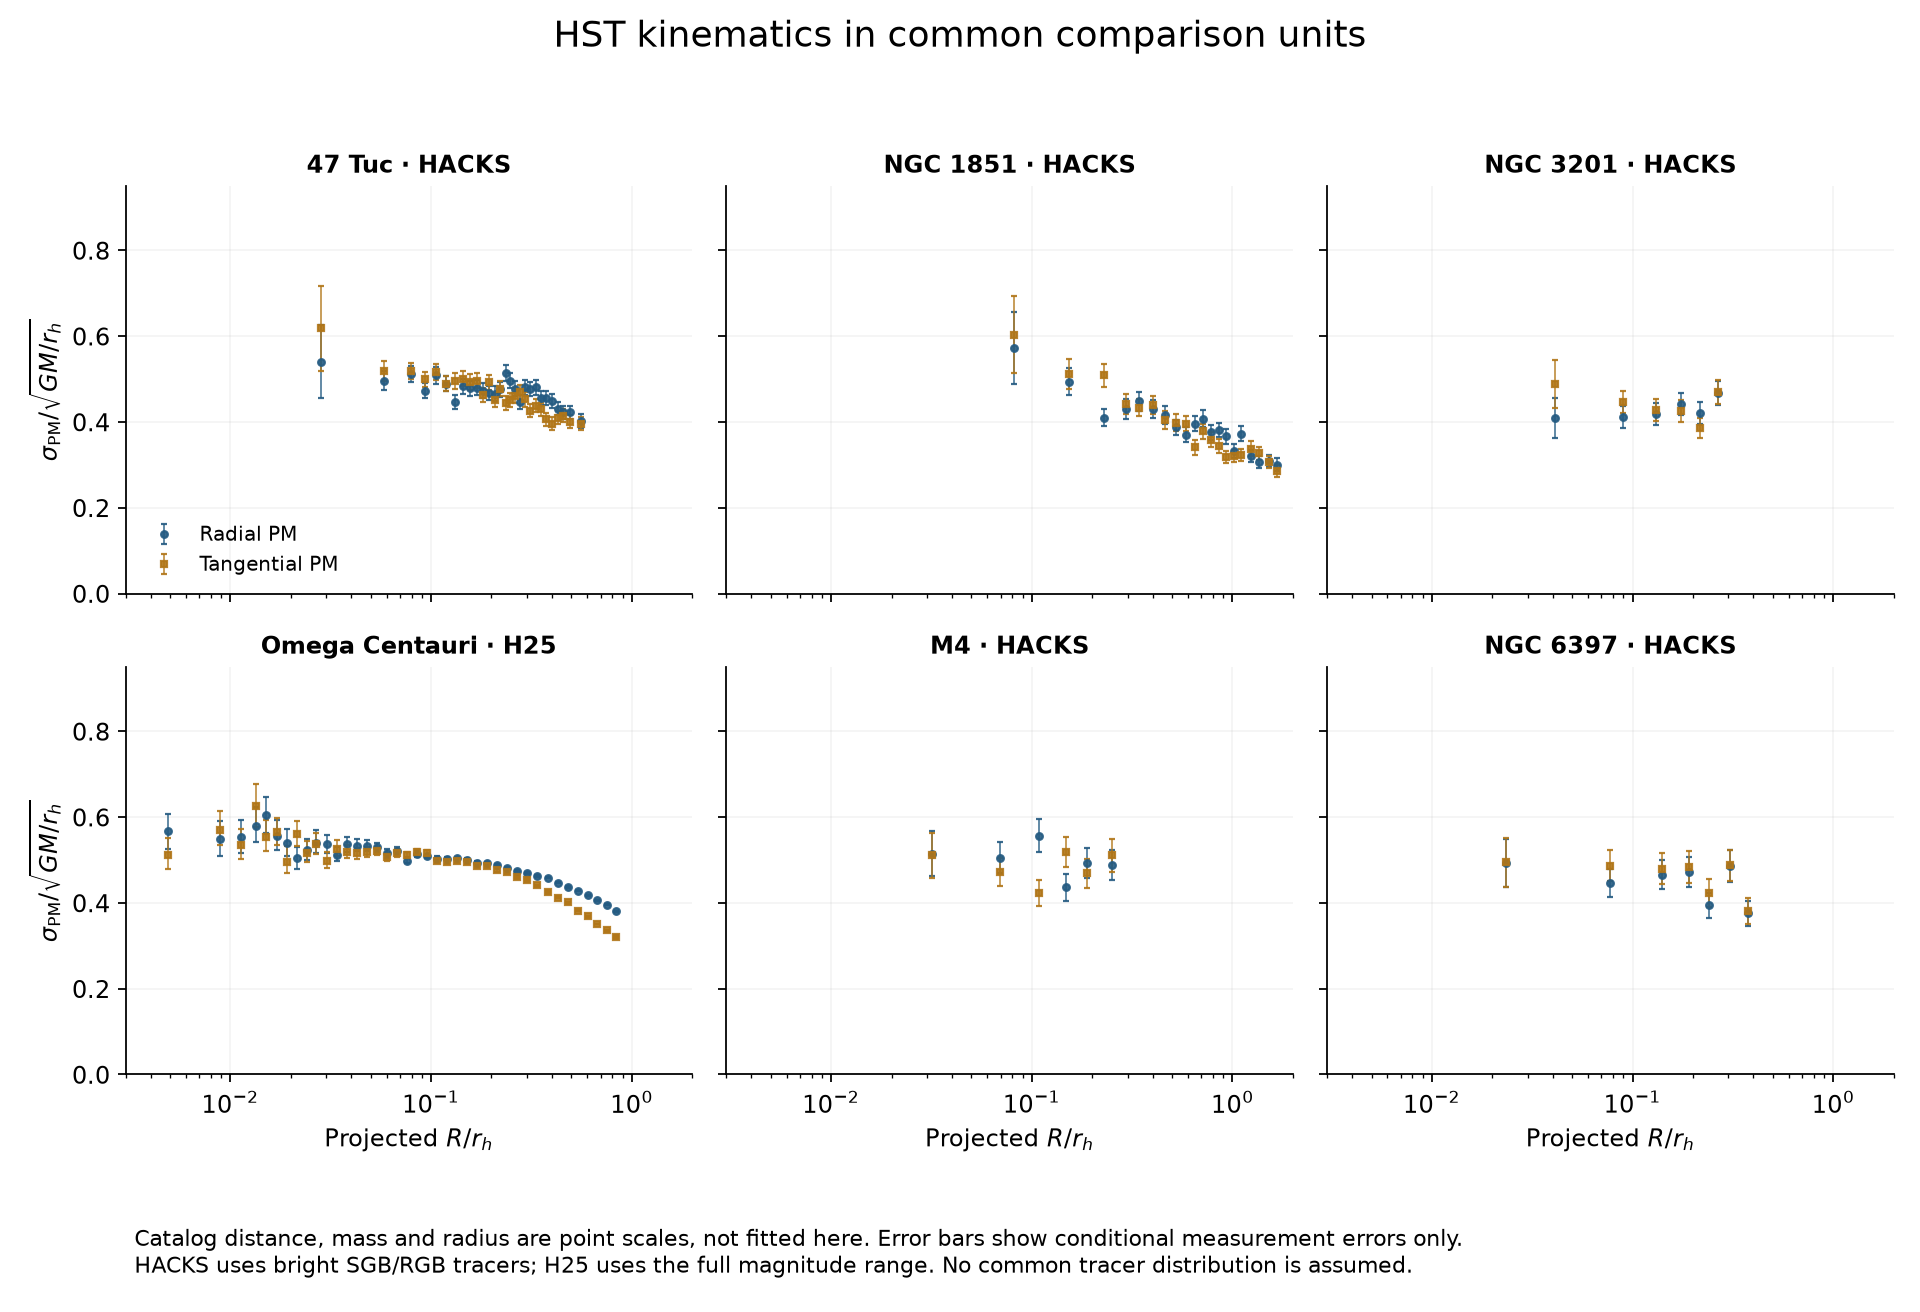

In [5]:
display(Image(filename=str(out / "hst_common_scales.png"), width=1050))

## Actual radial sampling

The intersection of median-radius spans is approximately 0.081–0.251 in projected R/rh. It is not exact annular overlap; HACKS bin boundaries are missing. No profile was interpolated or forced onto a shared radial grid.

,cluster,hst_radial_bins,hst_R_over_rh_min,hst_R_over_rh_max,compiled_quarantined_rows
0,NGC0104,28,0.0282,0.5569,0
1,NGC1851,20,0.0811,1.6747,4
2,NGC3201,6,0.0411,0.2680,0
3,NGC5139,40,0.0049,0.8315,1
4,NGC6121,6,0.0318,0.2513,0
5,NGC6397,7,0.0235,0.3750,15


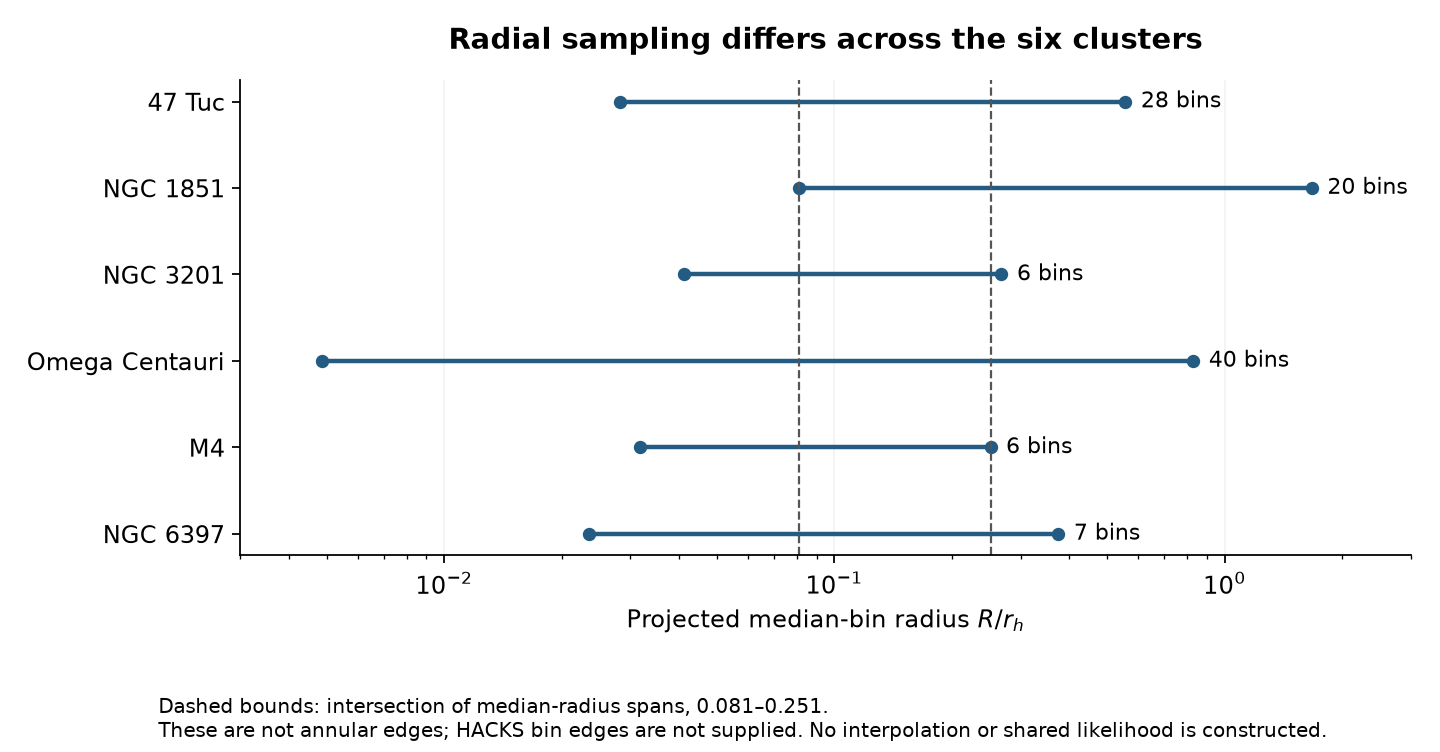

In [6]:
display(pd.read_csv(out / "coverage.csv")[["cluster", "hst_radial_bins",
        "hst_R_over_rh_min", "hst_R_over_rh_max", "compiled_quarantined_rows"]].round(4))
display(Image(filename=str(out / "radial_sampling.png"), width=900))

## Published joint host posteriors

The common 13-parameter schema is an interface, not a universal set of values. Complete weighted rows preserve dependencies. Medians below are summaries, not independently sampled distributions.

In [7]:
parameters = pd.read_csv(out / "posterior_parameters.csv")
selected = parameters[parameters.parameter.isin(["M", "rh", "d"])]
display(selected[["cluster", "parameter", "unit", "p16", "median", "p84"]].round(4))
diagnostics = json.loads((out / "posterior_diagnostics.json").read_text())
display(pd.DataFrame([{"cluster": d["cluster"], "joint_rows": d["rows"],
                       "posterior_ESS": d["posterior_ess"],
                       "mass_radius_correlation": d["posterior_correlation"][1][2]}
                      for d in diagnostics]).round(4))

,cluster,parameter,unit,p16,median,p84
1,NGC0104,M,Msun,8.996108e+05,9.044719e+05,9.094273e+05
2,NGC0104,rh,pc,6.678800e+00,6.713700e+00,6.749100e+00
12,NGC0104,d,kpc,4.408000e+00,4.420400e+00,4.431400e+00
14,NGC1851,M,Msun,3.210923e+05,3.250052e+05,3.287732e+05
15,NGC1851,rh,pc,3.669800e+00,3.712200e+00,3.756800e+00
25,NGC1851,d,kpc,1.210620e+01,1.218330e+01,1.226760e+01
27,NGC3201,M,Msun,1.698748e+05,1.756541e+05,1.814339e+05
28,NGC3201,rh,pc,9.070100e+00,9.597700e+00,1.015160e+01
38,NGC3201,d,kpc,4.602500e+00,4.635800e+00,4.671100e+00
40,NGC5139,M,Msun,3.069317e+06,3.082428e+06,3.148904e+06


,cluster,joint_rows,posterior_ESS,mass_radius_correlation
0,NGC0104,9064,5495.3122,0.3265
1,NGC1851,11111,5171.3955,-0.2352
2,NGC3201,11363,5782.0267,0.9003
3,NGC5139,18621,6888.6852,0.9442
4,NGC6121,11330,5843.8416,0.3165
5,NGC6397,12838,6617.7655,0.7818


All six ESS values reproduce the published two-decimal summaries. Twelve parameter rows differ beyond three-decimal rounding in means or standard deviations: the original summary averages resampled-run statistics, while this notebook reports direct empirical weighted moments. This supports interpretation of the chains, not exact fit reproduction or model adequacy.

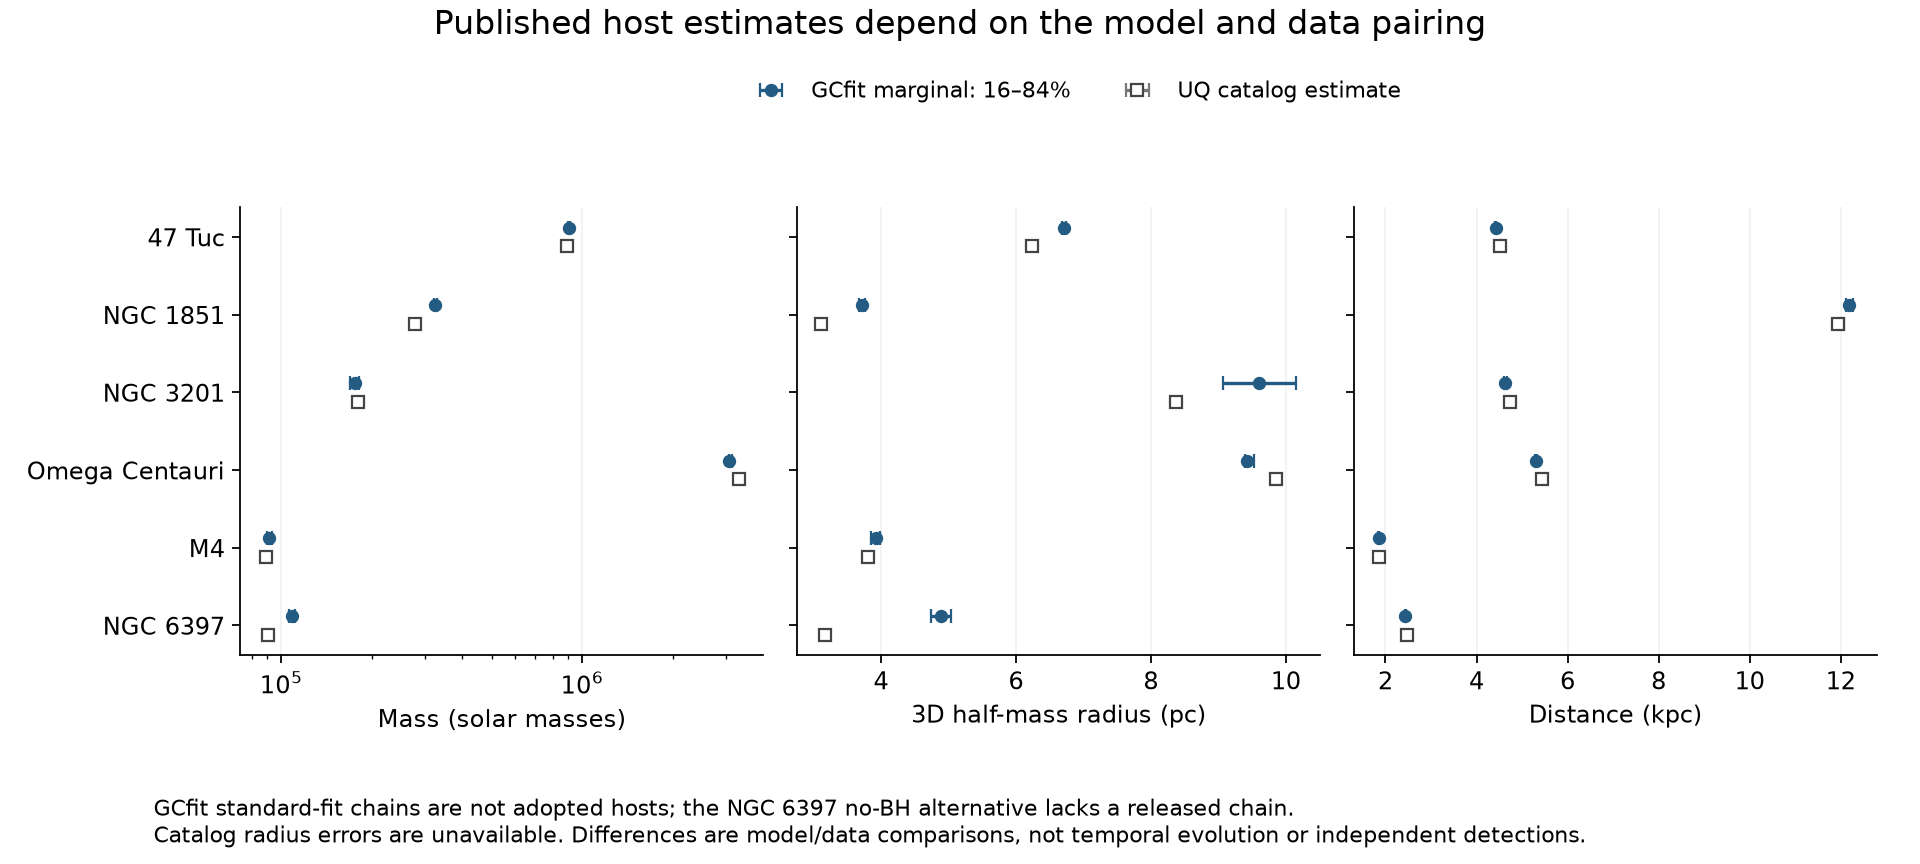

In [8]:
display(Image(filename=str(out / "host_estimate_comparison.png"), width=1050))

## Takeaways and handoff

- Use the same field names, units, source conventions and host interface for every cluster, while preserving a separate joint posterior for each.
- NGC 3201 and 47 Tuc are initial fit-reproduction candidates. NGC 1851 and M4 broaden the structure comparison. NGC 6397 and Omega Centauri require explicit model-sensitivity treatment.
- Before transport: establish compatible data/software/posterior pairing and reconstruct consistent species densities and velocity distributions. Published profile bands alone are insufficient.
- The observations do not determine remnant mass, merger-conditioned launch, kick distribution, encounter cutoffs or horizon. These remain unassigned.
- The paper and physical experiments are unchanged. See the repository's cluster data assessment and common host schema for source caveats and downstream requirements.